# MRAF and the signal region

**Question:** How does mixed-region amplitude freedom trade efficiency for an accurate shaped potential, on a disc and on a ring, and how far can the mixing parameter go?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 and 02 of this topic and notebook 01 of topic 03
- **Reading time:** about 50 minutes

## Objectives

A trap array wants light at points. A shaped potential, a disc, a ring or a line, wants light spread over a region with a prescribed profile, and the experiment cares about the profile: a flat disc traps a gas with uniform density, a ring carries a persistent current. Plain Gerchberg-Saxton, run with the shape as the target and zero everywhere else, gives a poor profile, and mixed-region amplitude freedom (MRAF) lets some of the light go elsewhere so that the profile can be flat. Its smooth start is itself a hologram, accurate and dark, and the notebook scores it, so that what the iterations add is measured against where they began. You will measure both on a disc and on a ring, sweep the mixing parameter to see where the accuracy comes from and what it costs, and test the one choice the method leaves to the user, the start.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import copy
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.core import score
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m08_mraf
import slmsuite
from slmsuite.holography.algorithms import Hologram

slmsuite.configure_logging(None)  # no console log inside the outputs

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))


def shape_numbers(phi, target, setup):
    """The product's two numbers of a shape: the error (``score.signal_error_pct`` over 100) and the power
    fraction in the signal region."""
    field = forward.fft_focal_field(phi, setup)
    error = score.signal_error_pct(field, target, setup) / 100.0
    return error, np.sum(np.abs(field[target.mask]) ** 2) / setup.n_pix**2

numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence.
- File read: `data/examples/cases.json`, case C04: a disc of 15 um radius on the 256 by 256 pixel SLM, whose device (4 bits and crosstalk) is not used here; a copy of its record with a ring of 20 um radius and 8 um width gives the second shape.

In [2]:
# case C04 gives the SLM, the beam and the disc; a copy of its record with a ring target gives the second shape
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec_disc = records["C04_disc_crosstalk"]
rec_ring = copy.deepcopy(rec_disc)
rec_ring["target"] = {"kind": "shaped", "shape": "ring", "radius_um": 20.0, "width_um": 8.0, "signal_margin_bins": 3}
setup = setup_of(rec_disc)
shapes = {"disc": target_of(rec_disc), "ring": target_of(rec_ring)}
seed = rec_disc["seed"]
for name, target in shapes.items():
    print(f"{name}: {int((target.amplitude > 0).sum())} bins, signal region {int(target.mask.sum())} bins")

disc: 2861 bins, signal region 3389 bins
ring: 4064 bins, signal region 5432 bins


## Method

A shaped target is a target amplitude $T$ inside a signal region SR, drawn on the focal grid. In plain Gerchberg-Saxton the focal field is replaced by $T$ inside SR and by zero outside, which forces every bit of light that does not fit the shape into the shape. MRAF (Pasienski and DeMarco 2008, Eq. 1, https://doi.org/10.1364/OE.16.002176) keeps a noise region NR outside SR and replaces the field by
$$G^{(n)} = \big\{ m\,T\big|_{SR} + (1-m)\,|E^{(n)}|\big|_{NR} \big\} e^{i\arg E^{(n)}},\qquad \phi^{(n+1)} = \arg\mathcal{F}^{-1}G^{(n)},$$
so inside SR the amplitude is forced to $mT$ and in NR it keeps $(1-m)$ of what the hologram made. Power the shape does not need drains into NR. With $m = 1$ the method is plain Gerchberg-Saxton, whose update is that of Di Leonardo et al. (2007, https://doi.org/10.1364/OE.15.001913) with zero noise. The signal region of the product is the shape dilated by 3 bins, so the dark margin around the shape counts as signal. Two numbers measure a result: the error $\eta = \sqrt{\langle((sI - T^2)/T^2)^2\rangle}$ over the shape eroded by one resolution cell (two bins), with $s$ the factor that rescales the intensity to the target, which is Eq. 2 of the same paper, and the fraction of the input power that lands in SR.

First the comparison itself. The cell runs plain Gerchberg-Saxton (M04) and MRAF (M08, mixing 0.3, the product's default) on the disc and on the ring for the 30 iterations of the case, and scores each hologram with the two numbers above, computed in the notebook from the focal field. The error that each method puts in its own history is printed next to it, as a check that the score is the method's.

In [3]:
# GS (zero noise region) and MRAF with mixing 0.3 on both shapes, 30 iterations, the engine's own start
budget = Budget(rec_disc["budget"]["iterations"])
runs = {}
for shape, target in shapes.items():
    runs[(shape, "M04")] = m04_gs.run(setup, target, budget=budget, rng=Rng(seed))
    runs[(shape, "M08")] = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=0.3)
for (shape, name), res in runs.items():
    err, eff = shape_numbers(res.phi, shapes[shape], setup)
    print(f"{shape} {name}: error = {err:.4f}, signal power fraction = {eff:.4f}")
    print(f"     history error of the method = {res.history[-1]['error']:.4f}")

disc M04: error = 0.4411, signal power fraction = 0.9621
     history error of the method = 0.4411
disc M08: error = 0.0517, signal power fraction = 0.1719
     history error of the method = 0.0517
ring M04: error = 0.2340, signal power fraction = 0.9632
     history error of the method = 0.2340
ring M08: error = 0.0373, signal power fraction = 0.1814
     history error of the method = 0.0373


The mixing parameter is the knob. The cell runs MRAF on the disc for $m$ equal to 0.1, 0.2, 0.3, 0.5 and 0.7 and prints the error and the signal power for each; $m = 1$ is the Gerchberg-Saxton run of the previous cell.

In [4]:
# the trade-off: the mixing parameter from 0.1 (noise region almost free) to 0.7, on the disc
sweep = {}
for mixing in (0.1, 0.2, 0.3, 0.5, 0.7):
    res = m08_mraf.run(setup, shapes["disc"], budget=budget, rng=Rng(seed), mixing=mixing)
    sweep[mixing] = shape_numbers(res.phi, shapes["disc"], setup)
    err, eff = sweep[mixing]
    print(f"m = {mixing:.1f}: error = {err:.4f}, signal power fraction = {eff:.4f}")
sweep[1.0] = shape_numbers(runs[("disc", "M04")].phi, shapes["disc"], setup)

m = 0.1: error = 0.0371, signal power fraction = 0.0123
m = 0.2: error = 0.0272, signal power fraction = 0.0621
m = 0.3: error = 0.0517, signal power fraction = 0.1719
m = 0.5: error = 0.2882, signal power fraction = 0.7407
m = 0.7: error = 0.3852, signal power fraction = 0.9485


MRAF does not say where to start. The product starts from a Fresnel lens phase of 20 waves at the edge of the aperture, a smooth hologram whose focal field is a broad spot. The cell runs MRAF with the same mixing from a uniform random phase instead, drawn through the seed, and prints the same two numbers next to those of the Fresnel start.

In [5]:
# the start matters: the engine's smooth Fresnel start against a uniform random phase, same mixing 0.3
random_start = m08_mraf.run(setup, shapes["disc"], budget=budget, rng=Rng(seed), mixing=0.3, start_waves=None)
err, eff = shape_numbers(random_start.phi, shapes["disc"], setup)
print(f"random start: error = {err:.4f}, signal power fraction = {eff:.4f}")
fresnel = shape_numbers(runs[("disc", "M08")].phi, shapes["disc"], setup)
print(f"Fresnel start: error = {fresnel[0]:.4f}, signal power fraction = {fresnel[1]:.4f}")

random start: error = 0.3004, signal power fraction = 0.1771
Fresnel start: error = 0.0517, signal power fraction = 0.1719


The start of MRAF is itself a hologram, a Fresnel lens of 20 waves at the edge of the aperture (the method's default), and it has an error of its own. The cell scores that start alone, on both shapes, with the same function as every other hologram of the notebook.

In [6]:
# the start alone, scored like every hologram: the Fresnel lens of 20 waves that MRAF begins from
x, y = geometry.slm_grid(setup)
fresnel_start = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
start_numbers = {shape: shape_numbers(fresnel_start, target, setup) for shape, target in shapes.items()}
for shape, (err, eff) in start_numbers.items():
    print(f"{shape}, the start alone: error = {err:.4f}, signal power fraction = {eff:.4f}")


disc, the start alone: error = 0.0322, signal power fraction = 0.0887
ring, the start alone: error = 0.0376, signal power fraction = 0.1297


Last, how fast the error falls. The cell prints the error of the disc at iterations 1, 5, 15 and 30 for Gerchberg-Saxton and for MRAF, from the histories, and runs MRAF on the disc for 100 iterations to see whether it keeps falling after the case's budget.

In [7]:
# the error of the disc against the iteration for GS and MRAF, from the history each method returns, and MRAF to 100
for name in ("M04", "M08"):
    errors = [h["error"] for h in runs[("disc", name)].history]
    picked = ", ".join(f"{errors[k - 1]:.3f}" for k in (1, 5, 15, 30))
    print(f"{name}: error at iteration 1, 5, 15, 30 = {picked}")
long_mraf = m08_mraf.run(setup, shapes["disc"], budget=Budget(100), rng=Rng(seed), mixing=0.3)
err, eff = shape_numbers(long_mraf.phi, shapes["disc"], setup)
print(f"M08 on the disc after 100 iterations: error = {err:.4f}, signal power fraction = {eff:.4f}")


M04: error at iteration 1, 5, 15, 30 = 1.156, 0.585, 0.466, 0.441
M08: error at iteration 1, 5, 15, 30 = 0.118, 0.120, 0.087, 0.052
M08 on the disc after 100 iterations: error = 0.0268, signal power fraction = 0.1823


The first figure shows the focal power of the two disc holograms on a logarithmic scale, in a window of 160 by 160 bins around the axis, with the signal region drawn as a cyan contour.

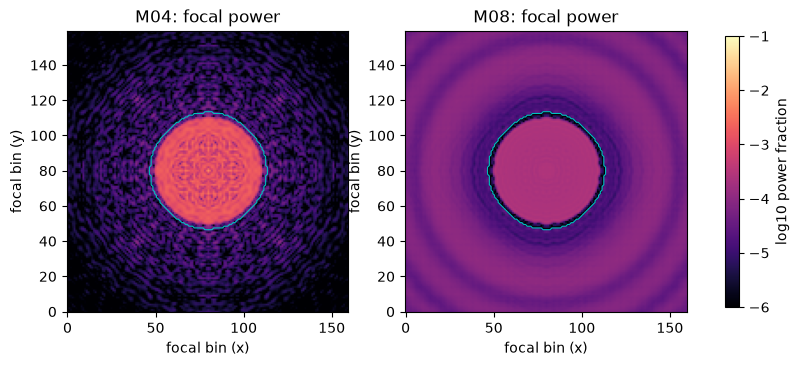

In [8]:
# the focal power of the disc for GS and for MRAF, a window of 160 x 160 bins around the axis, log scale
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
c = setup.n_fft // 2
for ax, name in zip(axes, ("M04", "M08")):
    power = np.abs(forward.fft_focal_field(runs[("disc", name)].phi, setup)) ** 2 * setup.pad**2 / setup.n_pix**2
    window = np.log10(power[c - 80:c + 80, c - 80:c + 80] + 1e-9)
    im = ax.imshow(window, origin="lower", vmin=-6, vmax=-1, cmap="magma")
    ax.contour(shapes["disc"].mask[c - 80:c + 80, c - 80:c + 80], levels=[0.5], colors="c", linewidths=0.8)
    ax.set_title(f"{name}: focal power")
    ax.set_xlabel("focal bin (x)")
    ax.set_ylabel("focal bin (y)")
fig.colorbar(im, ax=axes, label="log10 power fraction", shrink=0.8)
plt.show()

Plain Gerchberg-Saxton fills the disc with a pattern of ripples that has the symmetry of the SLM, and outside the contour there is only a weak background: all the light is in the signal region, and it is not flat. MRAF has a flat disc with a clean edge and fills the region outside the contour with rings of faint light several times fainter than the disc on the logarithmic scale, which is the noise region at work. That light is not wasted by accident: it is where the light that the flat disc cannot use goes. The figure does not show that the profile is flat to a given number, which the error does, nor what the rings would do to an experiment: a potential made of the disc and a halo is not the potential of the disc.

The second figure has two panels. On the left, the error (red, left axis, logarithmic) and the signal power (blue, right axis) against the mixing parameter for the disc. On the right, the error against the iteration for Gerchberg-Saxton and MRAF.

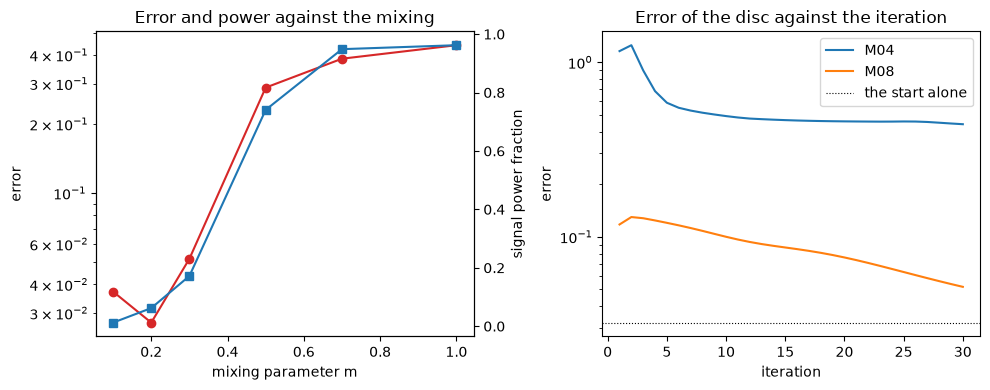

In [9]:
# left: error and efficiency against the mixing parameter; right: the error of the disc against the iteration
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
mixes = sorted(sweep)
ax1.semilogy(mixes, [sweep[m][0] for m in mixes], "o-", color="C3", label="error")
ax1.set_xlabel("mixing parameter m")
ax1.set_ylabel("error")
twin = ax1.twinx()
twin.plot(mixes, [sweep[m][1] for m in mixes], "s-", color="C0", label="signal power fraction")
twin.set_ylabel("signal power fraction")
ax1.set_title("Error and power against the mixing")
for name in ("M04", "M08"):
    history = runs[("disc", name)].history
    ax2.semilogy([h["iteration"] for h in history], [h["error"] for h in history], label=name)
ax2.axhline(start_numbers["disc"][0], color="k", ls=":", lw=0.8, label="the start alone")
ax2.set_xlabel("iteration")
ax2.set_ylabel("error")
ax2.set_title("Error of the disc against the iteration")
ax2.legend()
fig.tight_layout()
plt.show()

On the left, both curves rise with $m$: from 0.2 to 0.7 the signal power goes from 0.0621 to 0.9485 and the error from 0.0272 to 0.3852, so every gain in efficiency costs accuracy, and at $m = 1$ the method is plain Gerchberg-Saxton with its error of 0.4411 and its 0.9621 of the power in the signal region. The error is not monotone at the low end: at $m = 0.1$ it is 0.0371 and the signal region holds only 0.0123 of the power, so the lowest error of the sweep is at $m = 0.2$, where the method is already 12 times less efficient than at $m = 0.5$. On the right the error of Gerchberg-Saxton stalls near 0.44 after 15 iterations. MRAF stays far below it, but not below its own start: the Fresnel start alone scores 0.0322 (the dotted line), the first iteration jumps to 0.118, and the error then falls to 0.052 at the thirtieth, still above the start; run to 100 iterations the disc reaches 0.0268, below the start, with 0.1823 of the power in the signal region against the start's 0.0887. The 30 iterations of the case therefore buy power on this disc, about twice the start's, and the accuracy of the start is regained only later.

## State of the art

slmsuite is an open-source Python library for computing holograms on SLMs, and its MRAF is the reference that users of the field run for shaped potentials. In its `Hologram` the target amplitude is an array on the padded Fourier grid, a pixel set to NaN is a noise region, and the flag `mraf_factor` multiplies the noise region by a number. With the notation of the Method section, slmsuite keeps the signal amplitude and scales the noise region, which is DinHot's mixing $m$ with the factor $(1-m)/m$; for $m = 0.3$ the factor is 7/3. Every other setting stays at slmsuite's default. The inputs are those of the product: the same signal region, the same normalized Gaussian beam, 30 iterations, and for the first run the same Fresnel start as M08, passed through the `phase` argument.

The cell runs slmsuite's MRAF on the disc and on the ring and prints, next to the numbers of M08 from the Method section, the error and the signal power of each.

In [10]:
# slmsuite's MRAF on both shapes: noise region = NaN, factor (1 - m) / m for m = 0.3, the Fresnel start of M08
x, y = geometry.slm_grid(setup)
fresnel = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
beam = geometry.input_amplitude(setup)
factor = (1 - 0.3) / 0.3
slm = {}
for shape, target in shapes.items():
    goal = np.where(target.mask, target.amplitude, np.nan)
    holo = Hologram(goal, slm_shape=(setup.n_pix, setup.n_pix), amp=beam, phase=fresnel.copy())
    holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
    slm[shape] = np.array(holo.get_phase(), dtype=float)
    ours = shape_numbers(runs[(shape, "M08")].phi, target, setup)
    theirs = shape_numbers(slm[shape], target, setup)
    print(f"{shape} M08: error = {ours[0]:.4f}, signal power fraction = {ours[1]:.4f}")
    print(f"{shape} slmsuite: error = {theirs[0]:.4f}, signal power fraction = {theirs[1]:.4f}")

disc M08: error = 0.0517, signal power fraction = 0.1719
disc slmsuite: error = 0.0517, signal power fraction = 0.1719
ring M08: error = 0.0373, signal power fraction = 0.1814
ring slmsuite: error = 0.0373, signal power fraction = 0.1814


A user who does not precondition gets slmsuite's own start, a random phase. The cell runs that case on the disc, seeded, and prints the same two numbers.

In [11]:
# slmsuite from its own default start, a random phase, on the disc: what a user gets without preconditioning
np.random.seed(seed)
goal = np.where(shapes["disc"].mask, shapes["disc"].amplitude, np.nan)
holo = Hologram(goal, slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
slm_random = np.array(holo.get_phase(), dtype=float)
err, eff = shape_numbers(slm_random, shapes["disc"], setup)
print(f"slmsuite, random start: error = {err:.4f}, signal power fraction = {eff:.4f}")

slmsuite, random start: error = 0.2866, signal power fraction = 0.1774


The figure compares the error of the shape for plain Gerchberg-Saxton, the product's MRAF and slmsuite's MRAF, on both shapes, on a logarithmic axis.

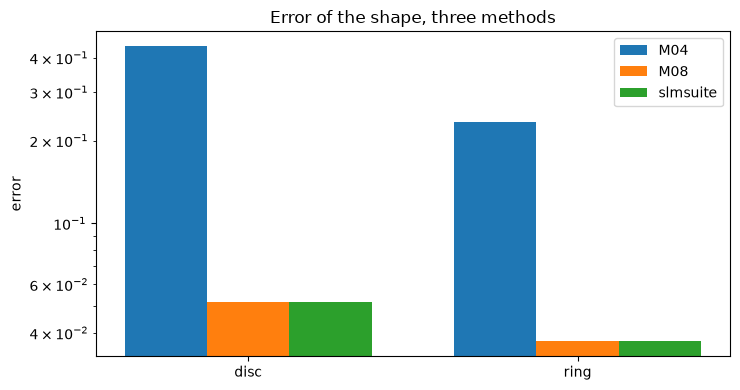

In [12]:
# the error of the shape for GS, the product's MRAF and slmsuite's MRAF, on both shapes, log axis
fig, ax = plt.subplots(figsize=(7.5, 4))
width = 0.25
rows = (("M04", {k: runs[(k, "M04")].phi for k in shapes}), ("M08", {k: runs[(k, "M08")].phi for k in shapes}),
        ("slmsuite", slm))
for k, (label, phis) in enumerate(rows):
    errors = [shape_numbers(phis[shape], shapes[shape], setup)[0] for shape in shapes]
    ax.bar(np.arange(2) + (k - 1) * width, errors, width, label=label)
ax.set_yscale("log")
ax.set_xticks(range(2), list(shapes))
ax.set_ylabel("error")
ax.set_title("Error of the shape, three methods")
ax.legend()
fig.tight_layout()
plt.show()

The bars of M08 and of slmsuite's MRAF have the same height on both shapes, and both are far below plain Gerchberg-Saxton, whose bars are 0.4411 on the disc and 0.2340 on the ring. The agreement is the point: the product's MRAF is the state of the art as the library implements it, when both start from the same phase, and the difference of 0.2866 against 0.0517 on the disc between slmsuite's random start and the Fresnel start says that the start is what a user must choose. The figure compares one mixing and 30 iterations, and it does not say how either implementation behaves at the other values of the mixing swept above.

## Results

**Answer:** Against plain Gerchberg-Saxton MRAF buys accuracy with efficiency, and the mixing parameter sets the price, in the product and in slmsuite alike. With the product's mixing of 0.3 the error of the profile is 0.0517 on the disc against 0.4411 for Gerchberg-Saxton, a factor of 8.5, and 0.0373 on the ring against 0.2340, a factor of 6.3, while the fraction of the input power in the signal region falls from 0.9621 to 0.1719 on the disc and from 0.9632 to 0.1814 on the ring. Against its own start the account is different: the Fresnel start alone already scores 0.0322 on the disc and 0.0376 on the ring, with only 0.0887 and 0.1297 of the power in the signal region, so on this case the 30 iterations raise the power about twofold at an error that is higher on the disc and equal on the ring, and the disc needs about 100 iterations (0.0268 with 0.1823) to go below its start. Along the disc sweep the error is 0.0272 at $m = 0.2$ with 0.0621 of the power in the signal region and 0.2882 at $m = 0.5$ with 0.7407; it does not keep falling below $m = 0.2$, since at $m = 0.1$ it is 0.0371. The start matters as much as the mixing: from a random phase the same method gets an error of 0.3004 instead of 0.0517. Run through slmsuite 0.5.0 from the same start and with the factor 7/3, MRAF gives the same numbers to four digits (0.0517 and 0.1719 on the disc, 0.0373 and 0.1814 on the ring), and from slmsuite's own random start the disc error is 0.2866. An accurate shaped potential from this method is therefore a potential that wastes most of its light, and the experiment has to have the power to spare.

## Summary

Gerchberg-Saxton cannot make a flat disc because it has nowhere to put the light the disc does not want; MRAF gives it a noise region, and a flat disc becomes possible at the price of five sixths of the power. On this disc the smooth start is already flat and darker still, so the iterations of MRAF are what bring the power up, and they need more than the case's 30 to bring the error below that of the start. The mixing parameter moves along that trade, with a best accuracy near $m = 0.2$ on this grid and a collapse of the advantage above $m = 0.5$, and the smooth start is part of the method. The next notebook asks whether a better start, an optimal-transport phase, changes the price.

## References

- Pasienski and DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json and https://pypi.org/project/slmsuite/.